# 05. Контрольный опыт: reconstruction и denoising
Небольшой TCN-AE обучается на одном и том же noisy input с двумя целями: observed -> observed и observed -> clean. Архитектура, инициализация, порядок train-batches и бюджет одинаковы. Checkpoint обеих моделей выбирается по validation endpoint clean MAE. Используется debug data seed 9001; это не подтверждающий протокол на независимых генеративных семьях. Чистый target доступен только благодаря синтетике.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "tsprep").is_dir() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook inside the tsprep project")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)

import pandas as pd

try:
    from IPython.display import display
except ImportError:
    display = print
from tsprep.evaluation.study_results import load_study_tables, task_summary
from tsprep.evaluation.visualize import plot_task_metric

def show_task(frame, metrics):
    if frame.empty:
        print("Нет данных для этой задачи. Отсутствующая метрика не заменяется нулём.")
    else:
        display(task_summary(frame, metrics))

In [2]:
from datetime import datetime, timezone
from tsprep.config import DataConfig, ModelConfig, TrainConfig, ExperimentConfig
from tsprep.data_preprocessing.synthetic import generate_series
from tsprep.data_preprocessing.datasets import prepare_and_window
from tsprep.experiment import train_experiment, evaluate_baselines, load_artifact
from tsprep.evaluation.examples import downstream_example

DEVICE = "cpu"
EPOCHS = 40
DATA_SEED, MODEL_SEED, LOADER_SEED = 9001, 317, 317
PILOT_DIR = ROOT/"results"/datetime.now(timezone.utc).strftime("denoising_pilot_%Y%m%dT%H%M%S%fZ")
sample = generate_series(length=2400, seed=DATA_SEED)
data_cfg = DataConfig(window_len=24, stride=2, batch_size=128, forecast_horizon=7, seed=LOADER_SEED)
model_cfg = ModelConfig(model_name="tcn_ae", hidden_dim=16, latent_dim=8, tcn_levels=2, dropout=0)
prepared = prepare_and_window(sample.values, data_cfg, is_anomaly=sample.is_anomaly)
baselines = evaluate_baselines(prepared, data_cfg, latent_dim=model_cfg.latent_dim, clean_raw=sample.clean_values)
print(PILOT_DIR, DEVICE, "parameters and seeds fixed before test")

e:\SSAU_code\НИР\results\denoising_pilot_20261104T115655133484Z cpu parameters and seeds fixed before test


## Две цели обучения
На вход обеих моделей поступают только наблюдаемые значения. Нормализатор обучается на observed train, затем применяется и к clean. Clean validation используется обеими ветками только для checkpoint selection; test в выборе не участвует. Эталонный clean test используется только при оценке. Стандартный study из ноутбука 03 от этого опыта не меняется.

In [3]:
pilot_metrics, pilot_examples = {}, {}
for arm, target in (("ordinary", "observed"), ("denoising", "clean")):
    experiment = ExperimentConfig(data_cfg, model_cfg,
        TrainConfig(epochs=EPOCHS, seed=MODEL_SEED, device=DEVICE, deterministic=True,
            training_target=target, validation_target="clean", selection_metric="endpoint_mae",
            early_stopping_patience=10))
    path = PILOT_DIR/arm
    pilot_metrics[arm] = train_experiment(experiment, sample.values, output_dir=path,
        clean_raw=sample.clean_values, is_anomaly=sample.is_anomaly,
        metadata={"purpose": "debug_pilot", "data_seed": DATA_SEED, "training_target": target}, verbose=False)
    pilot_examples[arm] = downstream_example(path, device=DEVICE, baselines=baselines)
    print(arm, "epochs:", pilot_metrics[arm]["epochs_ran"], "best:", pilot_metrics[arm]["best_epoch"],
        "validation endpoint clean MAE:", pilot_metrics[arm]["validation_score"])

ordinary epochs: 12 best: 2 validation endpoint clean MAE: 0.8355173411823454
denoising epochs: 12 best: 2 validation endpoint clean MAE: 0.8355015743346441


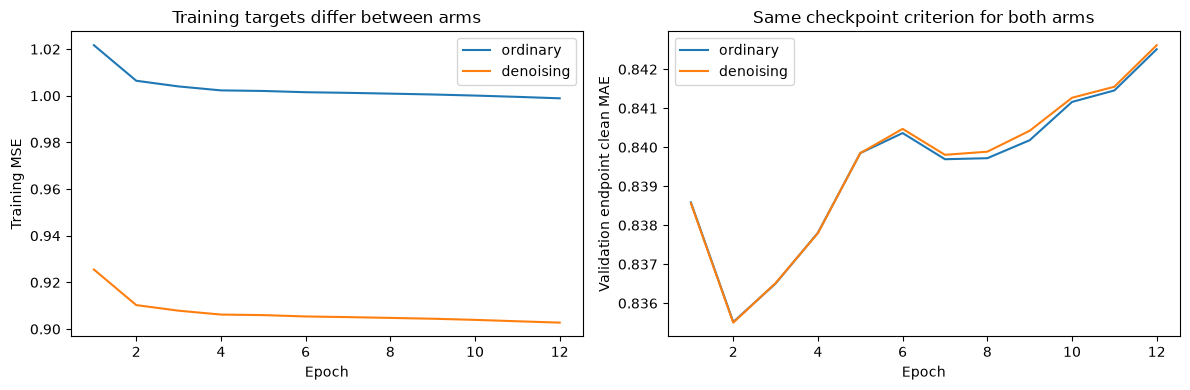

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for arm in ("ordinary", "denoising"):
    _, _, _, manifest, _ = load_artifact(PILOT_DIR/arm)
    h = manifest["history"]
    axes[0].plot(np.arange(1, len(h["train_recon"])+1), h["train_recon"], label=arm)
    axes[1].plot(np.arange(1, len(h["selection_loss"])+1), h["selection_loss"], label=arm)
axes[0].set(xlabel="Epoch", ylabel="Training MSE", title="Training targets differ between arms")
axes[1].set(xlabel="Epoch", ylabel="Validation endpoint clean MAE", title="Same checkpoint criterion for both arms")
for axis in axes:
    axis.legend()
fig.tight_layout()
plt.show()

## Простые baseline и раздельные ошибки
PCA той же размерности обучена только на observed train. Длина causal median выбирается из 3/5/9 по validation endpoint clean MAE; используется только прошлое и текущая точка. Mean - константа observed train. Для каждого метода показаны all/normal/contaminated endpoints. Здесь один data seed и один initialization seed, поэтому результаты описательные; подтверждение гипотезы и доверительные интервалы по независимым траекториям не заявляются.

In [5]:
from tsprep.data_preprocessing.datasets import prepare_and_window
clean_prepared = prepare_and_window(sample.clean_values, data_cfg, normalizer=prepared.normalizer)
reference = pilot_examples["ordinary"]
endpoint = reference["endpoint"]
normal = ~reference["anomaly"]["endpoint_labels"].astype(bool)
validation_clean = clean_prepared.val_windows[:, -1]
median_length = min((3, 5, 9), key=lambda k: np.abs(np.median(prepared.val_windows[:, -k:], axis=1)-validation_clean).mean())
methods = dict(observed_input=endpoint["observed"], PCA=endpoint["PCA"],
    train_mean=np.broadcast_to(prepared.raw_normalized[:prepared.split_bounds["train"][1]].mean(axis=0), endpoint["clean"].shape),
    causal_median=np.median(prepared.test_windows[:, -median_length:], axis=1),
    ordinary=pilot_examples["ordinary"]["endpoint"]["reconstructed"],
    denoising=pilot_examples["denoising"]["endpoint"]["reconstructed"])
pilot_rows = []
for method, values in methods.items():
    for subset, mask in (("all", np.ones(len(normal), bool)), ("normal", normal), ("contaminated", ~normal)):
        error = (values-endpoint["clean"])[mask]
        pilot_rows.append(dict(method=method, subset=subset, n=int(mask.sum()),
            mse=float(np.square(error).mean()) if mask.any() else None,
            mae=float(np.abs(error).mean()) if mask.any() else None))
pilot_table = pd.DataFrame(pilot_rows)
display(pilot_table)
print("Validation-selected causal median length:", median_length)
observed_all = pilot_table[(pilot_table.method == "observed_input") & (pilot_table.subset == "all")].iloc[0]
observed_normal = pilot_table[(pilot_table.method == "observed_input") & (pilot_table.subset == "normal")].iloc[0]
for arm in ("ordinary", "denoising"):
    overall = pilot_table[(pilot_table.method == arm) & (pilot_table.subset == "all")].iloc[0]
    ordinary_points = pilot_table[(pilot_table.method == arm) & (pilot_table.subset == "normal")].iloc[0]
    print(arm, "clean MAE / input:", overall.mae/observed_all.mae,
          "normal MSE / input:", ordinary_points.mse/observed_normal.mse)

,method,subset,n,mse,mae
0,observed_input,all,169,0.140522,0.094786
1,observed_input,normal,166,0.003430,0.046276
2,observed_input,contaminated,3,7.726299,2.779045
3,PCA,all,169,0.071362,0.183870
4,PCA,normal,166,0.045700,0.165141
5,PCA,contaminated,3,1.491279,1.220187
6,train_mean,all,169,0.880198,0.825350
7,train_mean,normal,166,0.888303,0.830858
8,train_mean,contaminated,3,0.431750,0.520593
9,causal_median,all,169,1.000444,0.822140


Validation-selected causal median length: 5
ordinary clean MAE / input: 8.65490926960547 normal MSE / input: 261.06945723315425
denoising clean MAE / input: 8.655113294233903 normal MSE / input: 261.0163016613351


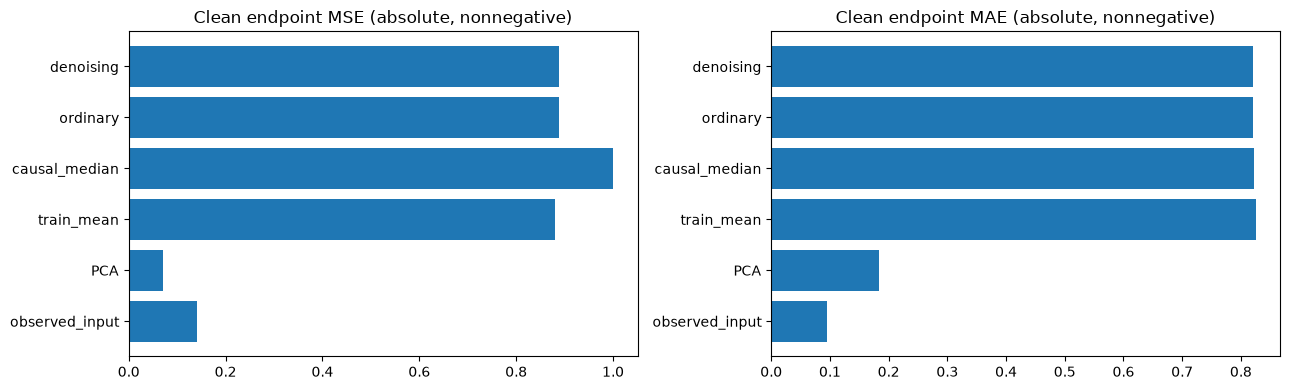

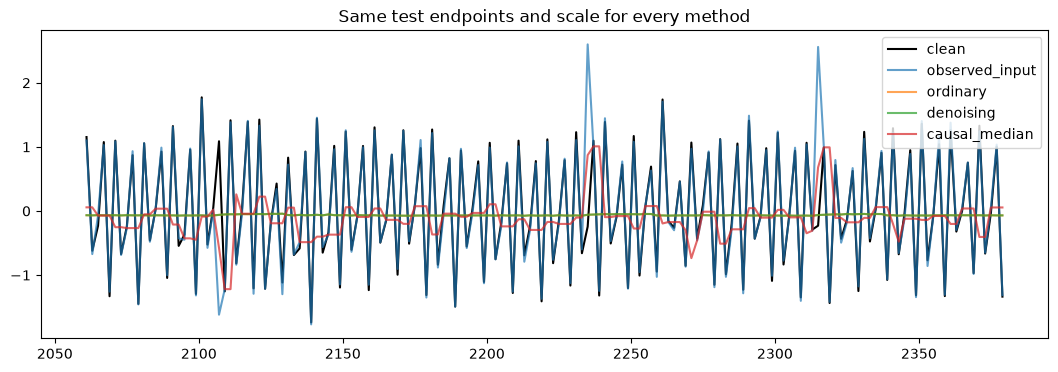

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, metric in zip(axes, ("mse", "mae")):
    subset = pilot_table[pilot_table.subset == "all"]
    axis.barh(subset.method, subset[metric])
    axis.set_title("Clean endpoint "+metric.upper()+" (absolute, nonnegative)")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(endpoint["time"][:160], endpoint["clean"][:160, 0], label="clean", color="black")
for method in ("observed_input", "ordinary", "denoising", "causal_median"):
    ax.plot(endpoint["time"][:160], methods[method][:160, 0], label=method, alpha=.7)
ax.legend()
ax.set_title("Same test endpoints and scale for every method")
plt.show()

## Отдельная downstream-проверка
Forecast target - наблюдаемое преобразованное значение ровно в t+7. Ошибки удаления загрязнений и ошибки прогноза не объединяются в одну оценку. Сравниваются z->Ridge, reconstructed window->Ridge, raw-window Ridge и PCA+Ridge; alpha выбирается только по validation. Эти значения не используются для повторного выбора denoising-модели.

In [7]:
forecast_rows = []
for arm, example in pilot_examples.items():
    f = example["forecast"]
    for method, prediction in f["predictions"].items():
        forecast_rows.append(dict(arm=arm, method=method, mae=float(np.abs(f["target"]-prediction).mean())))
display(pd.DataFrame(forecast_rows))
print("Это отладочный опыт. Для подтверждения нужны независимые траектории, несколько initialization seeds и trajectory-level intervals.")

,arm,method,mae
0,ordinary,embedding_ridge,0.419313
1,ordinary,train_mean,0.886756
2,ordinary,train_median,0.875735
3,ordinary,last_observed,1.638094
4,ordinary,raw_window_ridge,0.219266
5,ordinary,PCA_ridge,0.224665
6,ordinary,reconstructed_window_ridge,0.413111
7,denoising,embedding_ridge,0.420762
8,denoising,train_mean,0.886756
9,denoising,train_median,0.875735


Это отладочный опыт. Для подтверждения нужны независимые траектории, несколько initialization seeds и trajectory-level intervals.
